# Continuous-response mean inference

The binary simulations remain available. Here the target is the population mean **E[Y] = 1**, with either homoskedastic or heteroskedastic real-valued labels. Prediction models are fixed before inference. The response and judge scores are never restricted to [0,1].

We report given-label and label-selection experiments separately. Training, independent error-pilot and RASI burn-in costs appear separately; a common nominal query budget does not imply equal total label cost.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from openppi import Mean, PPIData, get_method, split
from dataset.regression_sim import RegressionDGP
from model.learners import SimulationLearner
from config import Config


## One PPI++ regression run

`m(X)=1+0.8 X1-0.6 X2+0.4(X3²-1)` and `Y=m(X)+sigma(X)*epsilon`. The heteroskedastic case uses `sigma(X)=0.3+0.7*sigmoid(X1)`; the homoskedastic case uses 0.5. The judge scores are affine, noisy versions of m(X), with independent human noise.


In [2]:
dgp = RegressionDGP(noise='heteroskedastic')
sample = dgp.draw(2500, np.random.default_rng(42))
train, labeled, unlabeled = split(sample['features'], sample['y'],
                                  train_size=400, labeled_size=400, random_state=7)
model = SimulationLearner(Config(outcome_type='continuous', initial_prediction=1.), seed=0)
model.update(*train, sample_weight=np.ones(len(train[1])))
data = PPIData(labeled[1], model.predict(labeled[0]), model.predict(unlabeled))
result = get_method('PPI++').inference(data, target=Mean(outcome_type='continuous'), alpha=.05)
print('Exact population mean:', dgp.truth())
print('Label range:', (float(labeled[1].min()), float(labeled[1].max())))
print('Prediction range:', (float(data.unlabeled_predictions.min()), float(data.unlabeled_predictions.max())))
print('Estimate:', result.estimate)
print('95% confidence interval:', result.confidence_interval)


Exact population mean: 1.0
Label range: (-2.1759232635743, 5.6293571639724185)
Prediction range: (-1.540684505719762, 3.6231912752457394)
Estimate: 0.9530106840551644
95% confidence interval: (0.8632339062977178, 1.042787461812611)


## Repeated experiments

The saved results use **100 repetitions per case**, a pool of 2,000 rows, a 400-label nominal budget, 400 independent predictor-training labels and, where used, 200 independent error-pilot labels. RASI consumes 100 burn-in labels from its 400-label budget. Seeds and configuration are saved with the results.

Regenerate from the repository root:
```sh
python examples/simulation/regression.py --reps 100 --out examples/simulation/results_regression
```

ASI/BAI use held-out RMS-error scores; FTRL uses squared-error scores. RASI fits an absolute-error model on its own burn-in. StratPPI fixes sign(X1) strata with known weights (0.5, 0.5), plans counts with independent pilot variances, and draws fresh conditional samples at the same population size/budget. BAI uses a chosen cube-balancing design; these are regression extensions with their stated scores, not a claim of identical reproduction of every original paper experiment.


In [3]:
results_dir = Path('results_regression')
if not (results_dir / 'summary.csv').exists():
    raise FileNotFoundError('Run regression.py as described above to generate results.')
settings = json.loads((results_dir / 'config.json').read_text())
summary = pd.read_csv(results_dir / 'summary.csv')
print('Repetitions per case:', settings['reps'])
print('Predictor:', settings['predictor'])
print(summary[['case','group','method','coverage','mean_width','bias','rmse']].to_string(index=False))


Repetitions per case: 100
Predictor: rf
           case         group       method  coverage  mean_width      bias     rmse
  homoskedastic  given_labels   Label-only      0.94    0.246568 -0.007137 0.061119
  homoskedastic  given_labels          PPI      0.94    0.164735 -0.002560 0.045017
  homoskedastic  given_labels        PPI++      0.95    0.158798 -0.004171 0.043374
  homoskedastic  given_labels         PSPA      0.94    0.158527 -0.003614 0.043120
  homoskedastic  given_labels        RePPI      0.93    0.171081 -0.004572 0.043914
  homoskedastic  given_labels       CalPPI      0.92    0.152137 -0.003768 0.042990
  homoskedastic  given_labels LinearCalPPI      0.94    0.158409 -0.003435 0.043070
  homoskedastic select_labels  Uniform+IPW      0.94    0.158153 -0.002192 0.042023
  homoskedastic select_labels          ASI      0.94    0.158655  0.001743 0.039174
  homoskedastic select_labels          BAI      0.91    0.158096  0.001974 0.045404
  homoskedastic select_labels       

## Coverage, interval width and RMSE

Coverage error bars show **one Monte Carlo standard error**, with the dashed line at 0.95. Results from 100 repetitions have appreciable Monte Carlo uncertainty. Shorter intervals alone are not evidence of better inference when coverage is below nominal. Conditional sample allocation and additional pilot costs also matter when interpreting comparisons.


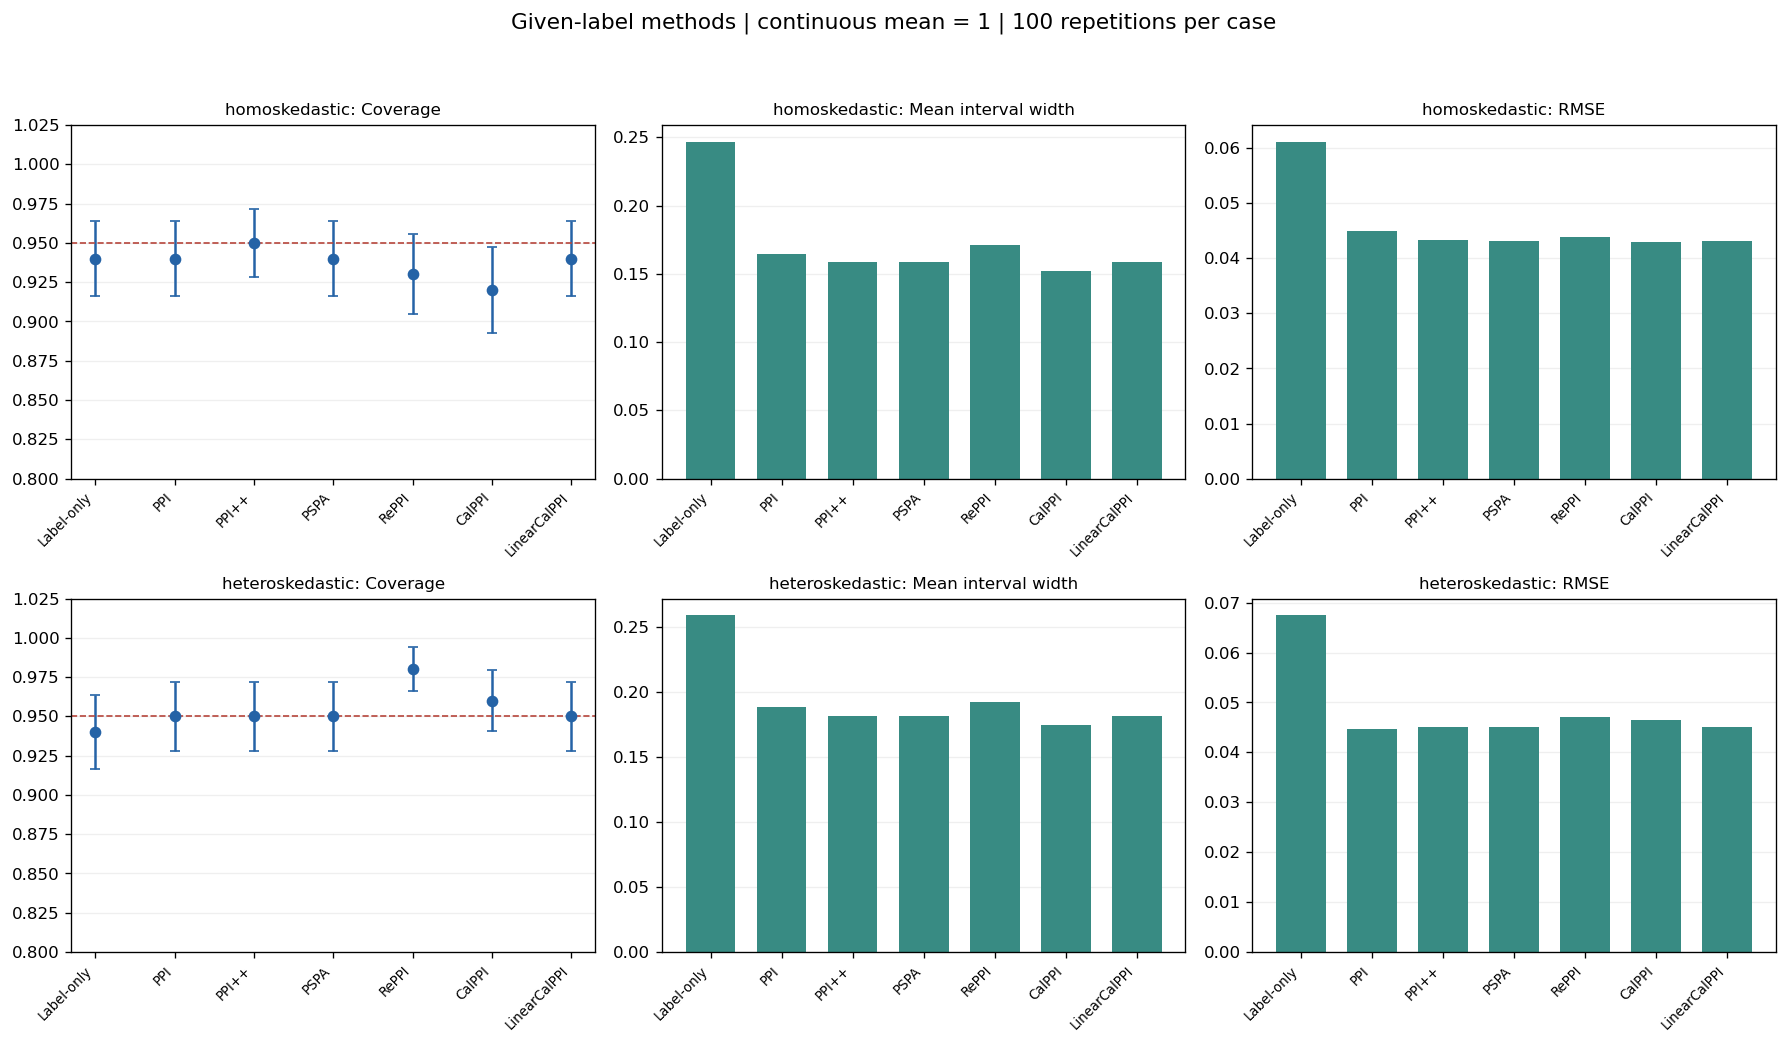

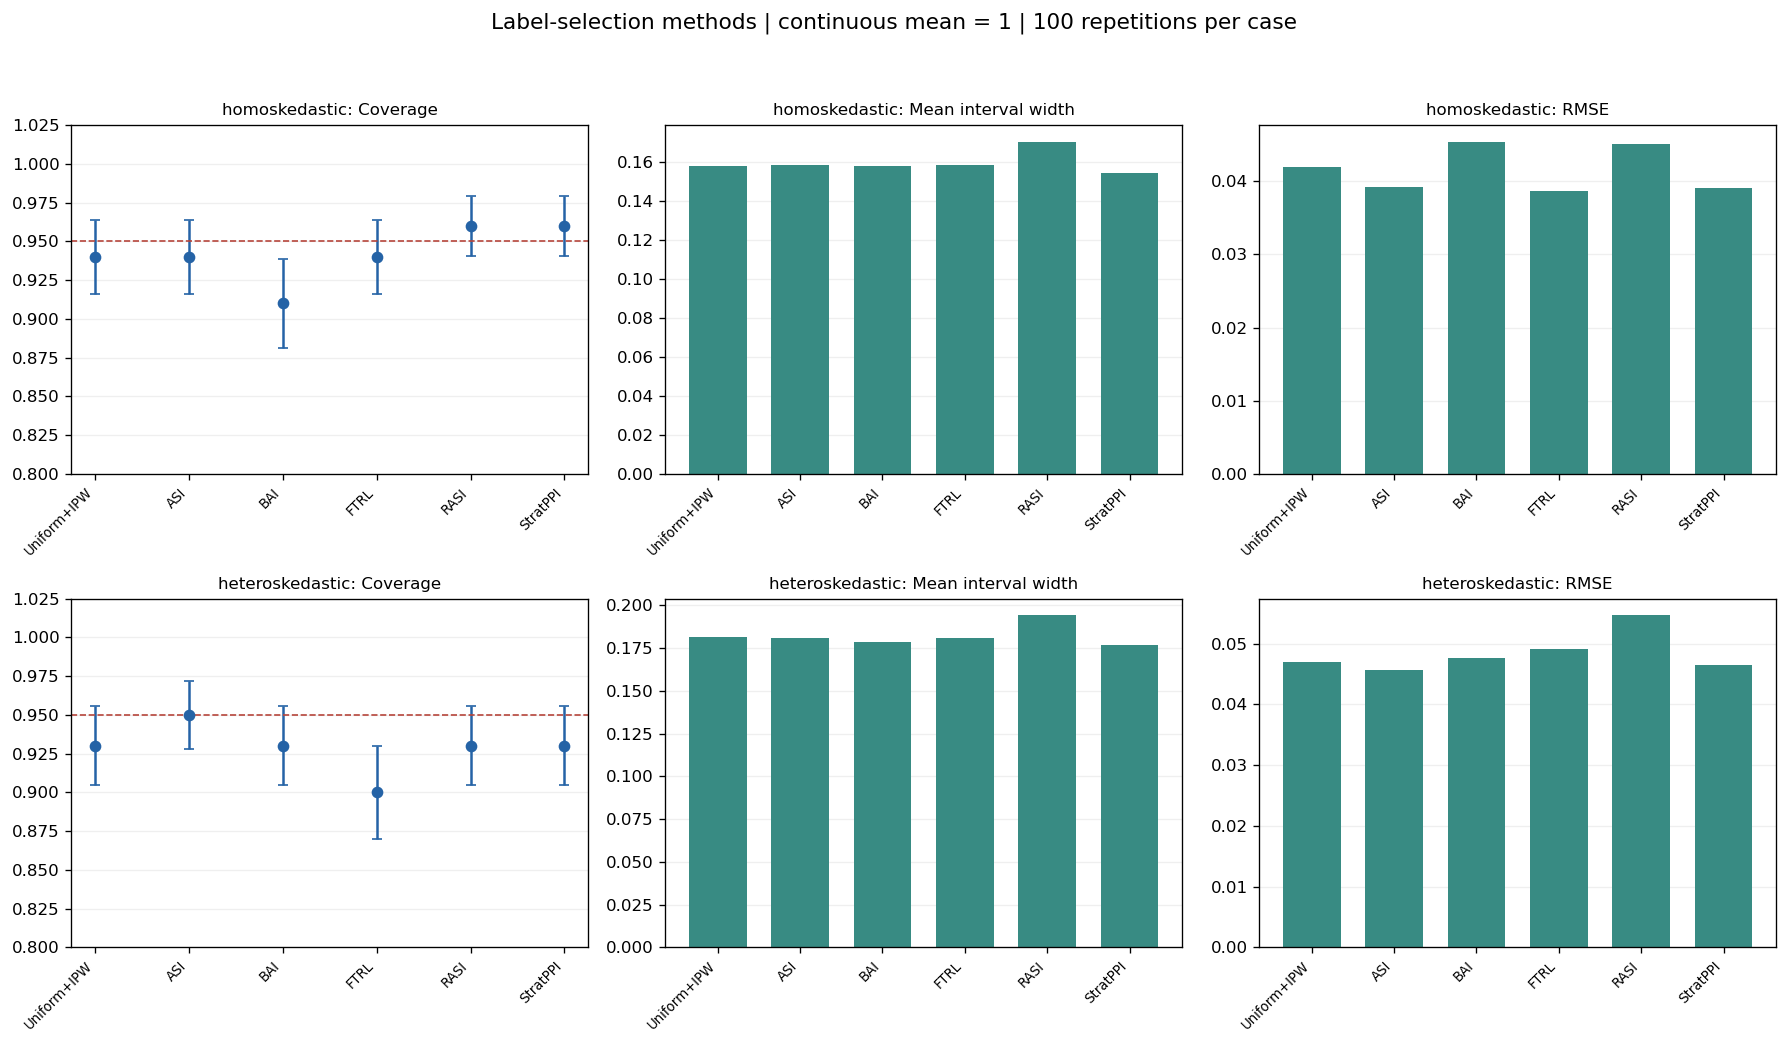

In [4]:
for group, title in [('given_labels', 'Given-label methods'), ('select_labels', 'Label-selection methods')]:
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    for row, noise in enumerate(('homoskedastic', 'heteroskedastic')):
        subset = summary[(summary.group == group) & (summary.case == noise)]
        x = np.arange(len(subset))
        names = subset.method.tolist()
        for col, (metric, label) in enumerate([('coverage','Coverage'), ('mean_width','Mean interval width'), ('rmse','RMSE')]):
            ax = axes[row, col]
            if metric == 'coverage':
                ax.errorbar(x, subset[metric], yerr=subset.coverage_mc_se, fmt='o', color='#2563a6', capsize=3)
                ax.axhline(.95, color='#b6453b', linestyle='--', linewidth=1)
                ax.set_ylim(.8, 1.025)
            else:
                ax.bar(x, subset[metric], color='#388b83', width=.7)
                ax.set_ylim(bottom=0)
            ax.set_xticks(x, names, rotation=45, ha='right', fontsize=8)
            ax.set_title(f'{noise}: {label}', fontsize=10)
            ax.grid(axis='y', alpha=.2)
            ax.set_axisbelow(True)
    fig.suptitle(f'{title} | continuous mean = 1 | {settings["reps"]} repetitions per case', fontsize=13)
    fig.tight_layout(rect=(0, .02, 1, .95))
    fig.savefig(results_dir / f'{group}.png', dpi=150, bbox_inches='tight')
    plt.show()


## Label costs

`actual_labels` includes inference queries plus burn-in. `total_labels` adds predictor-training and error-pilot labels. Pilot-free Uniform/RASI and pilot-based sampling designs therefore have different total costs. Bernoulli designs have random realized counts; cube and stratified designs use fixed counts here.


In [5]:
print(summary[['case','method','mean_actual_labels','training_labels','pilot_labels',
               'burn_in_labels','total_labels']].to_string(index=False))


           case       method  mean_actual_labels  training_labels  pilot_labels  burn_in_labels  total_labels
  homoskedastic   Label-only              400.00            400.0           0.0             0.0        800.00
  homoskedastic          PPI              400.00            400.0           0.0             0.0        800.00
  homoskedastic        PPI++              400.00            400.0           0.0             0.0        800.00
  homoskedastic         PSPA              400.00            400.0           0.0             0.0        800.00
  homoskedastic        RePPI              400.00            400.0           0.0             0.0        800.00
  homoskedastic       CalPPI              400.00            400.0           0.0             0.0        800.00
  homoskedastic LinearCalPPI              400.00            400.0           0.0             0.0        800.00
  homoskedastic  Uniform+IPW              399.17            400.0           0.0             0.0        799.17
  homosked

The new experiment keeps the predictor fixed. The online interface accepts continuous outcomes and explicit score callbacks, but online error-model updating is a separate experimental choice requiring honest historical residuals and query-probability weights. Cluster-PPI, MultiPPI and binary-only RG/MLE are outside this first regression benchmark.
